# Прогнозирование стоимости медицинской страховки

Ноутбук рассматривает датасет [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance).

В работе выполняется:

1. анализ данных о клиентах страховой компании;
2. обучение регрессионной модели, предсказывающей годовые расходы на медицинскую страховку (`charges`, доллары США) по характеристикам клиента;
3. сохранение обученной модели вместе со всеми этапами предобработки в виде **конвейера обработки данных** для последующего использования в веб-сервисе.

Признаки:

| Признак | Описание |
| --- | --- |
| `age` | возраст клиента, лет |
| `sex` | пол: `female` / `male` |
| `bmi` | индекс массы тела, кг/м² |
| `children` | число детей (иждивенцев), застрахованных по полису |
| `smoker` | курит ли клиент: `yes` / `no` |
| `region` | регион проживания в США: `northeast`, `northwest`, `southeast`, `southwest` |
| `charges` | **целевая переменная** — расходы на страховку, $ |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from seaborn import histplot, scatterplot, boxplot
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from pickle import dump
from pathlib import Path

## Загрузка и первичный анализ данных

In [2]:
df = pd.read_csv("../data/insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


Пропусков в данных нет. Проверим наличие дубликатов.

In [4]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


Найдена одна полностью повторяющаяся запись. Удалим дубликат, чтобы он не попал одновременно в обучающую и тестовую выборки.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(1337, 7)

In [6]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


Посмотрим на распределение категориальных признаков.

In [7]:
df["sex"].value_counts()

male      675
female    662
Name: sex, dtype: int64

In [8]:
df["smoker"].value_counts()

no     1063
yes     274
Name: smoker, dtype: int64

In [9]:
df["region"].value_counts()

southeast    364
southwest    325
northwest    324
northeast    324
Name: region, dtype: int64

## Анализ целевой переменной

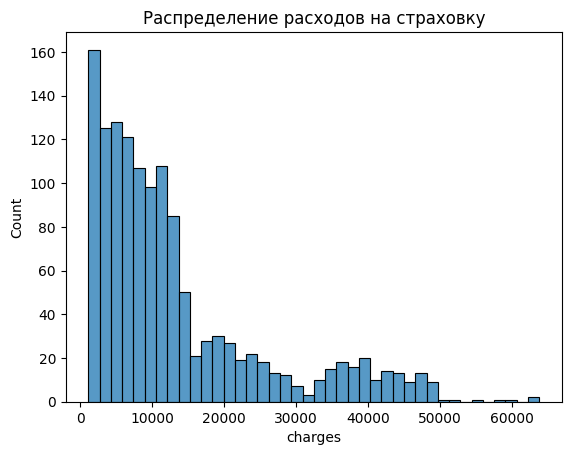

In [10]:
histplot(df["charges"], bins=40)
plt.title("Распределение расходов на страховку")
plt.show()

Распределение расходов сильно скошено вправо: у большинства клиентов расходы небольшие, но есть группа клиентов с очень высокими расходами. Выясним, с чем это связано.

In [11]:
df.groupby("smoker")["charges"].mean()

smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64

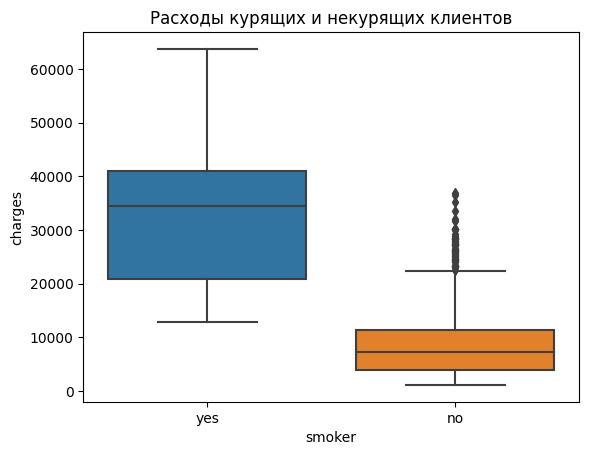

In [12]:
boxplot(data=df, x="smoker", y="charges")
plt.title("Расходы курящих и некурящих клиентов")
plt.show()

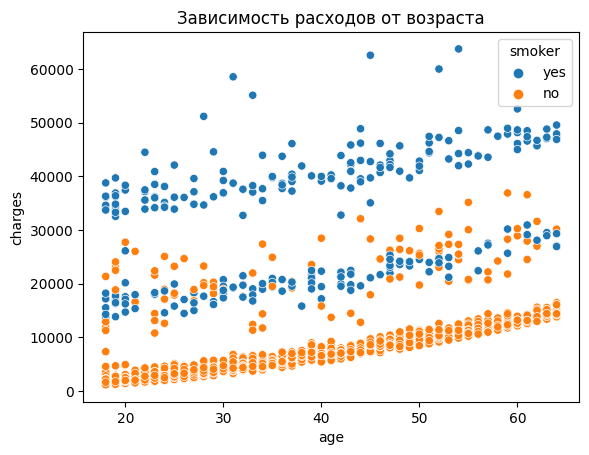

In [13]:
scatterplot(data=df, x="age", y="charges", hue="smoker")
plt.title("Зависимость расходов от возраста")
plt.show()

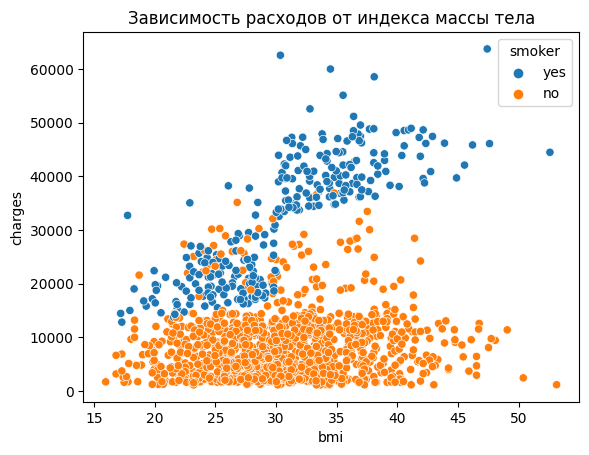

In [14]:
scatterplot(data=df, x="bmi", y="charges", hue="smoker")
plt.title("Зависимость расходов от индекса массы тела")
plt.show()

Выводы по анализу:

* курение — главный фактор: средние расходы курящих клиентов почти в 4 раза выше;
* расходы растут с возрастом;
* у курящих клиентов с индексом массы тела выше 30 расходы резко возрастают — признаки влияют на расходы **совместно** и **нелинейно**.

Поэтому кроме линейной модели стоит попробовать модель, которая умеет учитывать нелинейные зависимости, — градиентный бустинг над решающими деревьями.

## Конвейер предобработки данных

Количественные признаки: пропуски заполняются медианой, затем признаки стандартизируются.
Категориальные признаки: пропуски заполняются самым частым значением, затем применяется One-Hot кодирование.

В обучающих данных пропусков нет, но этапы заполнения пропусков нужны, чтобы сохранённый конвейер корректно обрабатывал неполные данные при инференсе.

In [15]:
numeric_features = ["age", "bmi", "children"]
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

In [16]:
categorical_features = ["sex", "smoker", "region"]
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot-encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
    ]
)

## Разделение на обучающую и тестовую выборки

In [18]:
features = numeric_features + categorical_features
X = df[features]
y = df["charges"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
X_train.shape, X_test.shape

((935, 6), (402, 6))

In [19]:
def evaluate(model, name):
    """Печатает метрики качества модели на обучающей и тестовой выборках."""
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    print(name)
    print(f"  R2 train: {r2_score(Y_train, pred_train):.3f}")
    print(f"  R2 test:  {r2_score(Y_test, pred_test):.3f}")
    print(f"  MAE test: {mean_absolute_error(Y_test, pred_test):.0f} $")
    rmse = mean_squared_error(Y_test, pred_test) ** 0.5
    print(f"  RMSE test: {rmse:.0f} $")

## Базовая модель: линейная регрессия

Подберём коэффициент регуляризации для гребневой регрессии (Ridge).

In [20]:
ridge_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", Ridge()),
    ]
)
ridge_search = GridSearchCV(
    ridge_pipe,
    {"regressor__alpha": np.linspace(0.1, 10.0, num=20)},
    cv=5,
    scoring="r2",
)
ridge_search.fit(X_train, Y_train)
print(ridge_search.best_params_)
evaluate(ridge_search, "Ridge")

{'regressor__alpha': 2.18421052631579}
Ridge
  R2 train: 0.736
  R2 test:  0.771
  MAE test: 4198 $
  RMSE test: 6255 $


Линейная модель объясняет около 77 % разброса расходов, но не может учесть совместное влияние курения и индекса массы тела.

## Основная модель: градиентный бустинг

Подберём число деревьев, их глубину и скорость обучения с помощью перекрёстной проверки на 5 блоках.

In [21]:
gb_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", GradientBoostingRegressor(random_state=42)),
    ]
)
param_grid = {
    "regressor__n_estimators": [100, 200, 300],
    "regressor__max_depth": [2, 3, 4],
    "regressor__learning_rate": [0.05, 0.1],
}
search_cv = GridSearchCV(gb_pipe, param_grid, cv=5, scoring="r2")
search_cv.fit(X_train, Y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('numeric',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['age',
                                                                          'bmi',
                                                                          'children']),
                                                                        ('categorical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehot-encoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['sex',
                                                                          'smoker',
                                                                          'region'])])),
                                       ('regressor',
                                        GradientBoostingRegressor(random_state=42))]),
             param_grid={'regressor__learning_rate': [0.05, 0.1],
                         'regressor__max_depth': [2, 3, 4],
                         'regressor__n_estimators': [100, 200, 300]},
             scoring='r2')

In [22]:
print("Best params:")
print(search_cv.best_params_)
print(f"Best CV R2: {search_cv.best_score_:.3f}")

Best params:
{'regressor__learning_rate': 0.05, 'regressor__max_depth': 3, 'regressor__n_estimators': 100}
Best CV R2: 0.850


In [23]:
evaluate(search_cv, "Gradient Boosting")

Gradient Boosting
  R2 train: 0.882
  R2 test:  0.875
  MAE test: 2560 $
  RMSE test: 4631 $


Градиентный бустинг заметно точнее линейной модели: коэффициент детерминации на тестовой выборке около 0,87, а средняя абсолютная ошибка уменьшилась примерно с 4 200 до 2 600 $.
Значения R² на обучающей и тестовой выборках близки, значит, модель не переобучилась.

Проверим модель на нескольких клиентах из тестовой выборки.

In [24]:
check = X_test.head(5).copy()
check["charges_true"] = Y_test.head(5).values
check["charges_pred"] = search_cv.predict(X_test.head(5)).round(2)
check

,age,bmi,children,sex,smoker,region,charges_true,charges_pred
899,49,22.515,0,male,no,northeast,8688.85885,10485.26
1063,29,25.600,4,female,no,southwest,5708.86700,7955.00
1255,51,36.385,3,female,no,northwest,11436.73815,12607.48
298,31,34.390,3,male,yes,northwest,38746.35510,38967.03
237,31,38.390,2,male,no,southeast,4463.20510,6448.57


## Сохранение конвейера

Сохраним лучший конвейер (предобработка + модель) для дальнейшего использования в веб-сервисе. На вход он принимает сырые данные клиента.

In [25]:
model = search_cv.best_estimator_

Path("../models").mkdir(parents=True, exist_ok=True)

with open("../models/pipeline.pkl", "wb") as file:
    dump(model, file)

Проверим, что сохранённый конвейер работает на сырых данных в том же формате, в котором их будет присылать клиент сервиса.

In [26]:
from pickle import load

with open("../models/pipeline.pkl", "rb") as file:
    loaded = load(file)

client = {"age": 19, "sex": "female", "bmi": 27.9, "children": 0,
          "smoker": "yes", "region": "southwest"}
loaded.predict(pd.DataFrame(client, index=[0]))

array([17765.47950311])